# skin 클래스 불균형 대응 — A안(class-weighted CrossEntropyLoss) 데모

**목적**: 교수님이 알려주신 또 다른 방식(B안)과 비교해서 팀이 선택할 수 있도록, 지금 harness(`modeling/src/train.py`)에 이미 구현해둔 **A안 — class-weighted CrossEntropyLoss**가 실제로 어떤 효과를 내는지 skin 데이터로 직접 실험하고 시각화합니다.

**A안 요약**: 비독성:독성 = 512:29(약 1:17.8)로 극심하게 불균형한 skin 라벨에서, 독성(소수 클래스) 샘플을 틀렸을 때의 손실(loss)에 더 큰 가중치를 곱해 모델이 소수 클래스를 더 적극적으로 맞히도록 유도하는 방식입니다. `train.py`의 `class_weights()` 함수를 그대로 가져와 사용합니다.

**비교 방법**: 같은 모델 구조·같은 데이터 분할로 "가중치 없음(plain CE)" vs "A안(weighted CE)" 두 가지를 각각 학습시켜, group 기준 5-fold 교차검증으로 성능을 비교합니다(단일 분할은 변동폭이 커서 신뢰 못함 — `skin_harness_cv_upgrade.ipynb`에서 이미 확인됨).

In [1]:
import sys
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\src")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (confusion_matrix, precision_recall_fscore_support,
                              roc_auc_score, average_precision_score)

from datasets import skin_dataset
from splits import grouped_kfold_splits
from train import class_weights  # A안의 핵심 함수 — 우리가 실제로 쓰는 코드 그대로 가져옴

skin_ds = skin_dataset(csv_path=r"C:\Users\UserK\학술제\skin irritation\skin_vectorized.csv")
print(f"skin 데이터: {len(skin_ds)}건, feature {skin_ds.input_dim}차원")
print("라벨 분포:", dict(zip(*np.unique(skin_ds.y, return_counts=True))))

skin 데이터: 541건, feature 2273차원
라벨 분포: {np.int64(0): np.int64(512), np.int64(1): np.int64(29)}


## 1. 클래스 불균형 현황 시각화

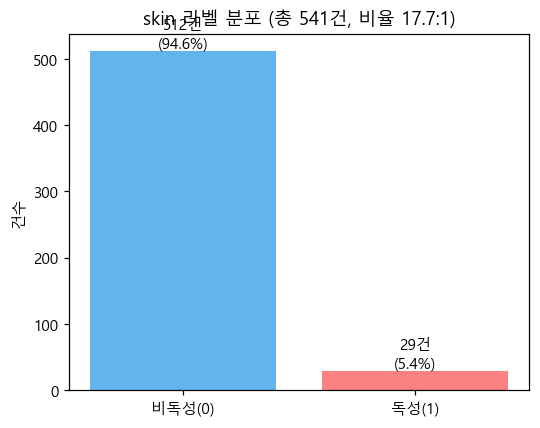

In [2]:
import matplotlib.pyplot as plt

counts = pd.Series(skin_ds.y).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["비독성(0)", "독성(1)"], [counts.get(0, 0), counts.get(1, 0)],
              color=["#63b3ed", "#fc8181"])
for b in bars:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width() / 2, h + 5, f"{int(h)}건\n({h/counts.sum()*100:.1f}%)",
            ha="center", fontsize=10)
ax.set_title(f"skin 라벨 분포 (총 {counts.sum()}건, 비율 {counts[0]/counts[1]:.1f}:1)")
ax.set_ylabel("건수")
plt.tight_layout()
plt.show()

## 2. A안 핵심 함수 — `class_weights()`

`train.py`에 있는 실제 함수입니다. 클래스별 샘플 수의 역수에 비례하게 가중치를 계산합니다
(`가중치 = 전체샘플수 / (클래스수 × 해당클래스샘플수)`).

In [3]:
import inspect
print(inspect.getsource(class_weights))

w = class_weights(skin_ds.y)
print("계산된 가중치:", w.tolist())
print(f"독성(1) 가중치가 비독성(0)보다 {w[1]/w[0]:.2f}배 큼")

def class_weights(labels, num_classes=2):
    counts = np.bincount(labels, minlength=num_classes).astype(np.float32)
    counts[counts == 0] = 1.0
    weights = counts.sum() / (num_classes * counts)
    return torch.tensor(weights, dtype=torch.float32)

계산된 가중치: [0.5283203125, 9.32758617401123]
독성(1) 가중치가 비독성(0)보다 17.66배 큼


## 3. 비교용 모델 정의

실제 `model.py`의 skin 쪽 구조(encoder 2개 Linear+ReLU+Dropout → head)를 그대로 가져온 단일 task 버전입니다.
plain/weighted 두 설정 모두 **완전히 동일한 구조**를 쓰고, 손실함수에 가중치를 주느냐만 다르게 합니다.

In [4]:
class SkinOnlyModel(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_classes=2, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, x):
        return self.net(x)


def train_one_fold(X_train, y_train, X_test, use_weight, seed, epochs=80, lr=1e-3, batch_size=32):
    torch.manual_seed(seed)
    model = SkinOnlyModel(X_train.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    if use_weight:
        criterion = nn.CrossEntropyLoss(weight=class_weights(y_train))
    else:
        criterion = nn.CrossEntropyLoss()

    X_t = torch.from_numpy(X_train)
    y_t = torch.from_numpy(y_train)
    n = len(X_t)

    model.train()
    for epoch in range(epochs):
        perm = torch.randperm(n)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            optimizer.zero_grad()
            logits = model(X_t[idx])
            loss = criterion(logits, y_t[idx])
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        logits = model(torch.from_numpy(X_test))
        proba = torch.softmax(logits, dim=1)[:, 1].numpy()
    return proba

## 4. Group 기준 5-fold 교차검증으로 plain vs weighted 비교

`splits.py`의 `grouped_kfold_splits()`(동일 조성 제형이 train/test로 갈라지지 않도록 보장)를 그대로 사용합니다.
각 fold마다 **같은 초기 가중치(동일 seed)**로 시작해 plain/weighted를 각각 학습시키고, out-of-fold 예측을 모읍니다.

In [5]:
folds = grouped_kfold_splits(skin_ds, n_splits=5, random_state=0)

oof_plain = np.zeros(len(skin_ds.y))
oof_weighted = np.zeros(len(skin_ds.y))

for fold_i, (train_idx, test_idx) in enumerate(folds):
    X_train, y_train = skin_ds.X[train_idx], skin_ds.y[train_idx]
    X_test = skin_ds.X[test_idx]

    oof_plain[test_idx] = train_one_fold(X_train, y_train, X_test, use_weight=False, seed=fold_i)
    oof_weighted[test_idx] = train_one_fold(X_train, y_train, X_test, use_weight=True, seed=fold_i)
    print(f"fold {fold_i+1}/5 완료 (test {len(test_idx)}건, 양성 {y_train.sum()}건 train에 포함)")

y_true = skin_ds.y
print("\n전체 OOF 예측 완료:", len(y_true), "건")

fold 1/5 완료 (test 109건, 양성 23건 train에 포함)
fold 2/5 완료 (test 108건, 양성 24건 train에 포함)
fold 3/5 완료 (test 108건, 양성 22건 train에 포함)
fold 4/5 완료 (test 109건, 양성 23건 train에 포함)
fold 5/5 완료 (test 107건, 양성 24건 train에 포함)

전체 OOF 예측 완료: 541 건


## 5. 결과 비교 — Confusion Matrix

In [6]:
def summarize(y_true, proba, label):
    pred = (proba >= 0.5).astype(int)
    cm = confusion_matrix(y_true, pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, pred, labels=[0, 1], zero_division=0)
    roc = roc_auc_score(y_true, proba)
    pr = average_precision_score(y_true, proba)
    print(f"--- {label} ---")
    print("Confusion Matrix (행=실제, 열=예측):\n", cm)
    print(f"독성(1) 클래스 — Precision {prec[1]:.3f} / Recall {rec[1]:.3f} / F1 {f1[1]:.3f}")
    print(f"ROC-AUC {roc:.3f} / PR-AUC {pr:.3f}")
    return {"cm": cm, "precision": prec[1], "recall": rec[1], "f1": f1[1], "roc_auc": roc, "pr_auc": pr}


result_plain = summarize(y_true, oof_plain, "plain (가중치 없음)")
print()
result_weighted = summarize(y_true, oof_weighted, "A안 (class-weighted CE)")

--- plain (가중치 없음) ---
Confusion Matrix (행=실제, 열=예측):
 [[498  14]
 [ 25   4]]
독성(1) 클래스 — Precision 0.222 / Recall 0.138 / F1 0.170
ROC-AUC 0.671 / PR-AUC 0.142

--- A안 (class-weighted CE) ---
Confusion Matrix (행=실제, 열=예측):
 [[422  90]
 [ 16  13]]
독성(1) 클래스 — Precision 0.126 / Recall 0.448 / F1 0.197
ROC-AUC 0.709 / PR-AUC 0.117


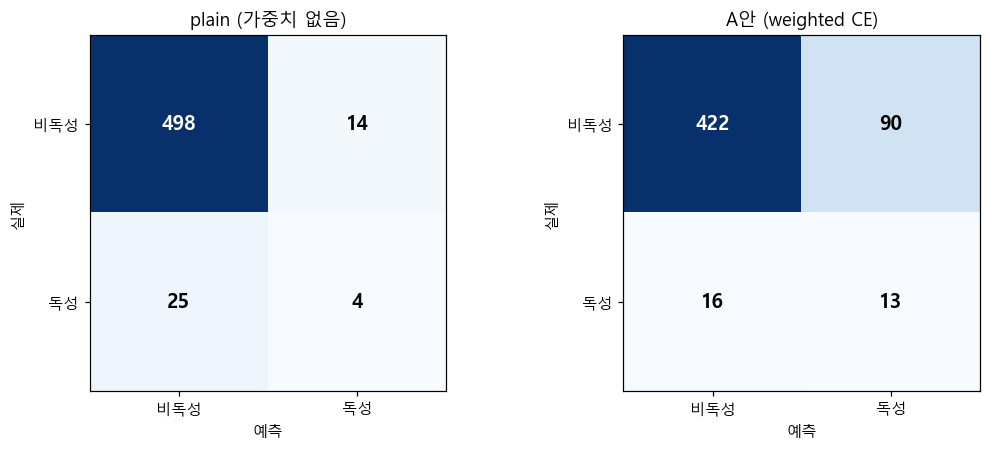

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, res, title in zip(axes, [result_plain, result_weighted], ["plain (가중치 없음)", "A안 (weighted CE)"]):
    im = ax.imshow(res["cm"], cmap="Blues")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["비독성", "독성"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["비독성", "독성"])
    ax.set_xlabel("예측"); ax.set_ylabel("실제")
    ax.set_title(title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(res["cm"][i, j]), ha="center", va="center",
                    fontsize=13, fontweight="bold",
                    color="white" if res["cm"][i, j] > res["cm"].max() / 2 else "black")
plt.tight_layout()
plt.show()

## 6. 지표 종합 비교

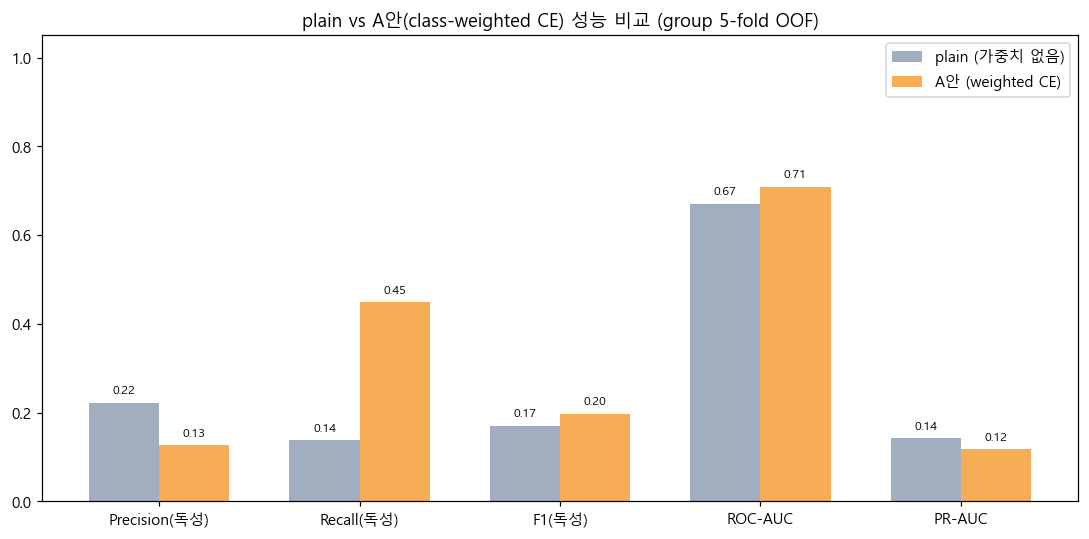

In [8]:
metrics = ["precision", "recall", "f1", "roc_auc", "pr_auc"]
metric_labels = ["Precision(독성)", "Recall(독성)", "F1(독성)", "ROC-AUC", "PR-AUC"]

plain_vals = [result_plain[m] for m in metrics]
weighted_vals = [result_weighted[m] for m in metrics]

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(metrics))
w = 0.35
ax.bar(x - w/2, plain_vals, width=w, label="plain (가중치 없음)", color="#a0aec0")
ax.bar(x + w/2, weighted_vals, width=w, label="A안 (weighted CE)", color="#f6ad55")
ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1.05)
ax.set_title("plain vs A안(class-weighted CE) 성능 비교 (group 5-fold OOF)")
ax.legend()
for i, (p, wv) in enumerate(zip(plain_vals, weighted_vals)):
    ax.text(i - w/2, p + 0.02, f"{p:.2f}", ha="center", fontsize=8)
    ax.text(i + w/2, wv + 0.02, f"{wv:.2f}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

## 한계 및 참고

- skin은 전체 541건 중 독성이 29건뿐이라, 5-fold로 나누면 fold당 평균 5~6건 — 지표(특히 Recall/F1)가 샘플 하나 차이로도 크게 흔들릴 수 있습니다. 여러 seed로 반복(`random_state` 변경)하면 더 안정적인 비교가 가능합니다.
- 여기서는 **plain vs A안(class-weighted CE)만** 비교했습니다. 교수님이 알려주신 B안을 받으면 같은 평가 틀(group 5-fold, 동일 지표)로 이 노트북에 이어서 비교 셀을 추가하면 됩니다.
- 모델 구조·학습 설정(epoch, lr, hidden_dim)은 `train.py` 기본값을 그대로 따랐습니다 — 실제 멀티태스크 모델(skin+eye 결합)과는 별도로, A안의 효과만 보기 위한 skin 단일 task 버전입니다.